In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

/home/jmaguire/miniforge3/envs/jconda_GPU/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/jmaguire/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1


In [12]:
import numpy as np
import struct
from array import array
from os.path import join

class MnistDataloader:
    def __init__(self, training_images_filepath,training_labels_filepath, test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath

    def read_images(self, images_filepath, labels_filepath):
        labels = []
        with open(labels_filepath, 'rb') as lbpath:
            magic, size = struct.unpack('>II', lbpath.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array('B', lbpath.read())

        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic)
            )
            image_data = array("B", file.read())
        images = []
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images.append(img)


        return images, labels

    def load_data(self):
        x_train, y_train = self.read_images(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train), (x_test, y_test)


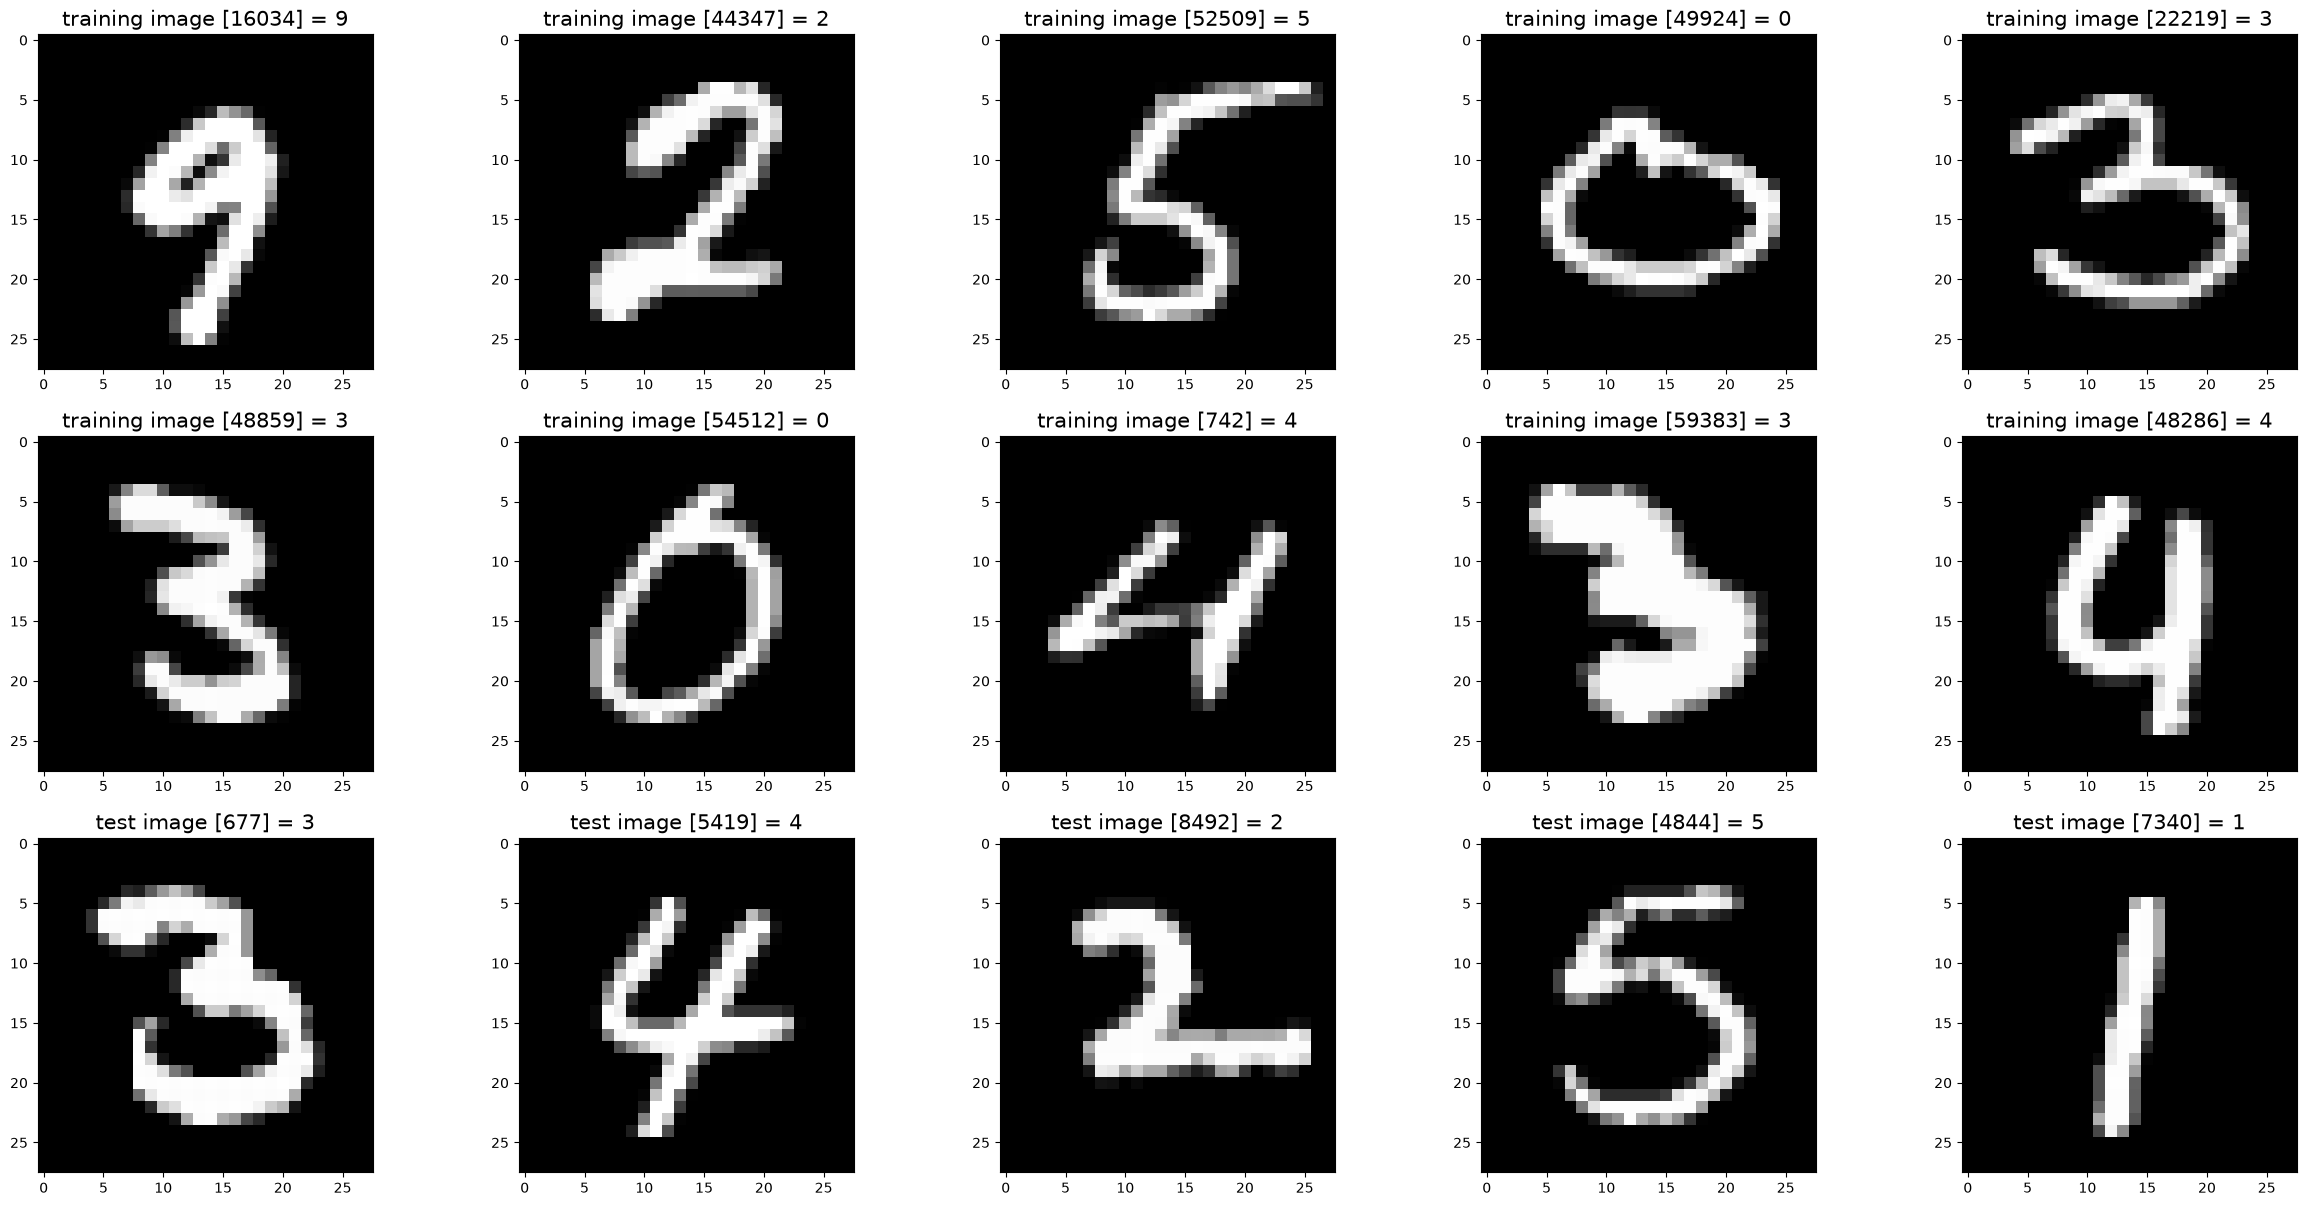

In [13]:
#
# Verify Reading Dataset via MnistDataloader class
#
%matplotlib inline
import random
import matplotlib.pyplot as plt
from os.path import join

#
# Set file paths based on added MNIST Datasets
#
input_path = '/home/jmaguire/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1'
training_images_filepath = join(input_path, 'train-images-idx3-ubyte/train-images-idx3-ubyte')
training_labels_filepath = join(input_path, 'train-labels-idx1-ubyte/train-labels-idx1-ubyte')
test_images_filepath = join(input_path, 't10k-images-idx3-ubyte/t10k-images-idx3-ubyte')
test_labels_filepath = join(input_path, 't10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
            index += 1

#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

#
# Show some random training and test images 
#
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(1, 60000)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)


In [17]:
from torch.utils.data import Dataset
import torch
import numpy as np


class MNISTTensorDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        lbl = self.labels[idx]


        img_tensor = torch.tensor(img, dtype=torch.float32).unsqueeze(0)
        lbl_tensor = torch.tensor(lbl, dtype=torch.long)

        return img_tensor, lbl_tensor

In [18]:
train_dataset = MNISTTensorDataset(x_train, y_train)

test_dataset = MNISTTensorDataset(x_test, y_test)

In [19]:
img_t, lbl_t = train_dataset[0]


print("Image tensor shape:", img_t.shape)
print("Label tensor shape:", lbl_t.shape)

Image tensor shape: torch.Size([1, 28, 28])
Label tensor shape: torch.Size([])


Label tensor looks empty, but it isn't, it is the box, it just has no preferred way for the data to flow in. Think of it like a box in satisfactory with one conveyor leading everything in, now think of image tensor as the same box with splitters feeding 3 boxes with specific items.

In [21]:
from torch.utils.data import DataLoader

torch.manual_seed(42)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=64,
    shuffle=False
)

images_batch, labels_batch = next(iter(train_loader))

print("Batch of images shape:", images_batch.shape)
print("Batch of labels shape:", labels_batch.shape)

Batch of images shape: torch.Size([64, 1, 28, 28])
Batch of labels shape: torch.Size([64])


In [24]:
import torch.nn as nn

class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        pass

    def forward(self, x):
        pass

In [29]:
import torch.nn as nn
import torch.nn.functional as F

class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(-1, 32 * 7 * 7)

        x = self.fc(x)

        return x

In [30]:
model = MNISTCNN()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)

images_batch, labels_batch = next(iter(train_loader))

images_batch = images_batch.to(device)

predictions = model(images_batch)

print("Predictions shape:", predictions.shape)

Predictions shape: torch.Size([64, 10])


In [31]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

In [32]:
labels_batch = labels_batch.to(device)

loss = criterion(predictions, labels_batch)

print("Loss:", loss.item())

Loss: 22.465370178222656


In [44]:
upgraded_model.train()

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = upgraded_model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    if batch_idx % 100 == 0:
        print(f'Batch {batch_idx}, Loss: {loss.item()}')

Batch 0, Loss: 2.2924869060516357
Batch 100, Loss: 0.22033703327178955
Batch 200, Loss: 0.13533687591552734
Batch 300, Loss: 0.08898444473743439
Batch 400, Loss: 0.023356257006525993
Batch 500, Loss: 0.39165255427360535
Batch 600, Loss: 0.03352686017751694
Batch 700, Loss: 0.029982592910528183
Batch 800, Loss: 0.08040062338113785
Batch 900, Loss: 0.007804427295923233


In [45]:
upgraded_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = upgraded_model(images)

        _, predicted = torch.max(outputs.data, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


accuracy = 100 * correct / total

print(f'Accuracy on test set (10000 images): {accuracy:.2f}%')

Accuracy on test set (10000 images): 98.03%


In [42]:
import torch.nn as nn
import torch.nn.functional as F

class UpgradedMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1)

        self.bn1 = nn.BatchNorm2d(16)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1)

        self.bn2 = nn.BatchNorm2d(32)

        self.fc1 = nn.Linear(32 * 7 * 7, 128)

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))

        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        x = x.view(-1, 32 * 7 * 7)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


In [43]:
import torch.optim as optim

upgraded_model = UpgradedMNISTCNN()
upgraded_model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(upgraded_model.parameters(), lr=0.1, momentum=0.9)

In [46]:
import os

model_path = "upgraded_mnist_cnn.pth"

torch.save(upgraded_model.state_dict(), model_path)

print(f"model saved to : {os.path.abspath(model_path)}")

model saved to : /home/jmaguire/upgraded_mnist_cnn.pth


In [47]:
loaded_model = UpgradedMNISTCNN()

loaded_model.load_state_dict(torch.load("upgraded_mnist_cnn.pth"))
loaded_model.to(device)

UpgradedMNISTCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)